## 1. Hugging Face Login

#### This imports the token from Kaggle Secrets, so make sure the secret is set correctly before running the code.

In [1]:
import os
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

print("Hugging Face login successful.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


## 2. Check GPU

In [3]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")

CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


## 3. Configuration

#### this is sample configuration, you are free to modify any parameter to train the best performing model

In [4]:
import os
import random
import json
import time
import math
import zipfile
import shutil

# Hugging Face dataset
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"

# You can use any of the 4 train files or all the files for pre-training the legal model
TRAIN_ACT_FILE = "Phase_1_Pretraining/Train/train_acts.json"
TRAIN_HC_FILE = "Phase_1_Pretraining/Train/train_high_courts.json"
TRAIN_SC_FILE = "Phase_1_Pretraining/Train/train_supreme_court.json"
TRAIN_TRI_FILE = "Phase_1_Pretraining/Train/train_tribunals.json"
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

# Training configuration
TRAIN_PROPORTIONS = {
    "acts": 0.25,
    "high_court": 0.25,
    "supreme_court": 0.25,
    "tribunals": 0.25,
}
VOCAB_SIZE = 20_000
TRAIN_TOKENS = 200_000_000
VAL_TOKENS = 5_000_000
TRAIN_BLOCK_SIZE = 2048
EPOCHS = 1 # NOT being used
SEED = 42
random.seed(SEED)
MODEL_CONTEXT_LENGTH = 2048
N_EMBD = 768      
N_LAYER = 12      
N_HEAD = 12       # d_head = 64
N_KV_HEAD = 4     # GQA: 3 query heads share each KV head
KV_LATENT_DIM = N_EMBD // 4 # 192

# Generation
TARGET_GENERATION_WORDS = 128
MAX_GENERATION_TOKENS = 384
TEMPERATURE = 0.7   # 0.1 == greedy -> repetition loops
TOP_P = 0.9
REPETITION_PENALTY = 1.1

# Kaggle output
OUTPUT_DIR = "/kaggle/working/cs781_phase1"
MODEL_OUTPUT_DIR = os.path.join(
    OUTPUT_DIR,
    "legal-gpt2-final"
)
PREDICTION_PATH = os.path.join(
    OUTPUT_DIR,
    "prediction.json"
)
SUBMISSION_ZIP = os.path.join(
    OUTPUT_DIR,
    "submission.zip"
)
LOSS_PLOT_PATH = os.path.join(
    OUTPUT_DIR,
    "training_validation_loss.png"
)
os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)
print("Configuration loaded.")

Configuration loaded.


## 4. Create Tokenizer

In [5]:
# %%writefile a1_tokenizer.py
"""Expose your Assignment-1 BPE implementation to Assignment 3.

Reuse your A-1 tokenizer code/class here. The important change is that it must be
RETRAINED on the `train_text` supplied by Assignment 3 rather than reusing a tokenizer
trained on the Assignment-1 dataset.
"""

''' Required returned interface:
      tokenizer.encode(text) -> sequence of integer ids
      tokenizer.decode(ids) -> string
      tokenizer.vocab_size OR tokenizer.get_vocab_size()'''
import re
from tqdm import tqdm
from collections import defaultdict, Counter

class ByteLevelBPE:
    def __init__(self, vocab_size=5000):
        self.vocab_size = vocab_size
        self.reserved = ["<pad>", "<unk>", "<s>", "</s>"]
        self.merges = []
        self.itos = list(self.reserved)
        self.stoi = {}
        self.ranks = {}
        self.merged_map = {}
        self._cache = {}
        # Regex pattern matching words, numbers, individual punctuation, and whitespace sequences
        pattern = r"""'s|'t|'re|'ve|'m|'ll|'d| ?[^\s\W\d_]+| ?\d+| ?[^\s\w]+|\s+(?!\S)|\s+"""
        self.pat = re.compile(pattern, re.UNICODE)
        
    def _split_text(self, text):
        """Splits text into chunks preserving whitespace, or falls back to basic regex split."""
        pattern = r"""'s|'t|'re|'ve|'m|'ll|'d| ?[^\s\W\d_]+| ?\d+| ?[^\s\w]+|\s+(?!\S)|\s+"""
        return re.findall(pattern, str(text), flags=re.UNICODE)

    def fit(self, texts, max_unique_words=200000):
        """Train a byte-level BPE tokenizer using inverted indexing for fast merging."""
        raw_counts = Counter()
        iterator = [texts] if isinstance(texts, str) else texts

        # Preserve whitespace tokens when populating initial raw_counts
        for text in tqdm(iterator, desc="Building word vocabulary"):
            for chunk in self._split_text(text):
                raw_counts[chunk] += 1

        if max_unique_words and len(raw_counts) > max_unique_words:
            most_common = raw_counts.most_common(max_unique_words)
            raw_counts = dict(most_common)

        word_freqs = {}
        pair_counts = defaultdict(int)
        pair_to_words = defaultdict(set)

        for word, count in raw_counts.items():
            encoded = word.encode("utf-8")
            byte_word = tuple(encoded[i:i+1] for i in range(len(encoded)))
            word_freqs[byte_word] = count

            for i in range(len(byte_word) - 1):
                pair = (byte_word[i], byte_word[i + 1])
                pair_counts[pair] += count
                pair_to_words[pair].add(byte_word)

        base_bytes = sorted({token for word in word_freqs for token in word})
        self.itos = list(self.reserved) + base_bytes
        self.merges = []

        target_merges = self.vocab_size - len(self.itos)

        with tqdm(total=target_merges, desc="Training BPE Merges") as pbar:
            while len(self.itos) < self.vocab_size:
                if not pair_counts:
                    break

                best_pair = max(pair_counts, key=lambda p: (pair_counts[p], p[0], p[1]))
                if pair_counts[best_pair] <= 0:
                    break

                merged_token = best_pair[0] + best_pair[1]
                self.merges.append((best_pair, merged_token))
                self.itos.append(merged_token)

                words_to_update = list(pair_to_words[best_pair])
                del pair_counts[best_pair]
                del pair_to_words[best_pair]

                p0, p1 = best_pair

                for word in words_to_update:
                    count = word_freqs.get(word, 0)
                    if count == 0:
                        continue

                    new_word = []
                    i = 0
                    n = len(word)

                    while i < n:
                        if i + 1 < n and word[i] == p0 and word[i + 1] == p1:
                            new_word.append(merged_token)
                            i += 2
                        else:
                            new_word.append(word[i])
                            i += 1

                    new_word = tuple(new_word)

                    for j in range(len(word) - 1):
                        old_p = (word[j], word[j + 1])
                        if old_p in pair_counts:
                            pair_counts[old_p] -= count
                            if pair_counts[old_p] <= 0:
                                del pair_counts[old_p]

                    for j in range(len(new_word) - 1):
                        new_p = (new_word[j], new_word[j + 1])
                        pair_counts[new_p] += count
                        pair_to_words[new_p].add(new_word)

                    del word_freqs[word]
                    word_freqs[new_word] = count

                pbar.update(1)

        self.vocab_size = len(self.itos)
        self.stoi = {token: idx for idx, token in enumerate(self.itos)}
        self.ranks = {pair: rank for rank, (pair, _) in enumerate(self.merges)}
        self.merged_map = {pair: merged for pair, merged in self.merges}
        self._cache = {}
        return self

    def encode_word(self, word):
        """Encode single word using memoization and local pair updates."""
        if word in self._cache:
            return self._cache[word]

        encoded = word.encode("utf-8")
        tokens = [encoded[i:i+1] for i in range(len(encoded))]

        if len(tokens) <= 1:
            res = [self.stoi.get(token, self.stoi["<unk>"]) for token in tokens]
            self._cache[word] = res
            return res

        while len(tokens) > 1:
            min_rank = float("inf")
            min_pair = None

            for i in range(len(tokens) - 1):
                pair = (tokens[i], tokens[i + 1])
                rank = self.ranks.get(pair, float("inf"))
                if rank < min_rank:
                    min_rank = rank
                    min_pair = pair

            if min_pair is None or min_rank == float("inf"):
                break

            merged = self.merged_map[min_pair]
            new_tokens = []
            i = 0
            n = len(tokens)
            p0, p1 = min_pair

            while i < n:
                if i + 1 < n and tokens[i] == p0 and tokens[i + 1] == p1:
                    new_tokens.append(merged)
                    i += 2
                else:
                    new_tokens.append(tokens[i])
                    i += 1
            tokens = new_tokens

        res = [self.stoi.get(token, self.stoi["<unk>"]) for token in tokens]
        self._cache[word] = res
        return res

    def encode(self, text):
        """Encode a sentence while preserving original spaces and newlines."""
        ids = [self.stoi["<s>"]]
        for chunk in self._split_text(text):
            ids.extend(self.encode_word(chunk))
        ids.append(self.stoi["</s>"])
        return ids

    def decode(self, ids):
        """Decode BPE token IDs back into text seamlessly."""
        byte_list = []
        for idx in ids:
            if 0 <= idx < len(self.itos):
                tok = self.itos[idx]
            else:
                tok = "<unk>"
            if tok not in self.reserved and isinstance(tok, bytes):
                byte_list.append(tok)
        try:
            return b"".join(byte_list).decode("utf-8", errors="ignore")
        except Exception:
            return ""

    def get_vocab_size(self):
        return self.vocab_size

def train_tokenizer(train_text: str, vocab_size: int):
    """Train A-1 BPE tokenizer on `train_text` and return the trained tokenizer."""
    tokenizer = ByteLevelBPE(vocab_size)
    tokenizer.fit(train_text)
    return tokenizer

## 5. Download Training Data From Hugging Face

In [6]:
# from huggingface_hub import hf_hub_download

# train_acts_file_path = hf_hub_download(repo_id=HF_DATASET_REPO, filename=TRAIN_ACT_FILE, repo_type="dataset", token=HF_TOKEN)
# train_hc_file_path = hf_hub_download(repo_id=HF_DATASET_REPO, filename=TRAIN_HC_FILE, repo_type="dataset", token=HF_TOKEN)
# train_sc_file_path = hf_hub_download(repo_id=HF_DATASET_REPO, filename=TRAIN_SC_FILE, repo_type="dataset", token=HF_TOKEN)
# train_tri_file_path = hf_hub_download(repo_id=HF_DATASET_REPO, filename=TRAIN_TRI_FILE, repo_type="dataset", token=HF_TOKEN)

# 5.5 Train Tokenizer

In [7]:
!pip install ijson

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.9/149.9 kB 3.5 MB/s eta 0:00:00a 0:00:01


In [8]:
import re
import unicodedata

# ── Step 1: Unicode normalization ─────────────────────────────────────────────
# Converts homoglyphs, ligatures, curly quotes, etc. to canonical ASCII/UTF-8.
# NFC is sufficient; NFKC is stronger (decomposes ligatures like ﬁ→fi).
def normalize_unicode(text: str) -> str:
    return unicodedata.normalize("NFKC", text)

# ── Step 2: Strip control characters (the main source of output 1 garbage) ────
# Keep: \t (tab), \n (newline), \r (carriage return).
# Kill: everything in \x00-\x1f except the three above, and \x7f, and
#       Unicode "format" category (soft hyphens, zero-width joiners, etc.)
_CTRL = re.compile(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f]")
_FMT  = re.compile(r"[\u00ad\u200b-\u200f\u202a-\u202e\u2060-\u206f\ufeff]")

def strip_control_chars(text: str) -> str:
    text = _CTRL.sub("", text)
    text = _FMT.sub("", text)
    return text

# ── Step 3: Fix OCR hyphenation artifacts ─────────────────────────────────────
# "consti-\ntution" → "constitution"
# Only merge when both sides are alphabetic (avoids destroying bullet "- item")
_HYPHEN_BREAK = re.compile(r"([a-zA-Z])-\n([a-zA-Z])")

def fix_hyphen_breaks(text: str) -> str:
    return _HYPHEN_BREAK.sub(r"\1\2", text)

# ── Step 4: Normalize whitespace ──────────────────────────────────────────────
# Collapse runs of spaces/tabs to one space.
# Collapse 3+ consecutive newlines to exactly 2 (preserve paragraph breaks).
_MULTI_SPACE = re.compile(r"[ \t]+")
_MULTI_NL    = re.compile(r"\n{3,}")

def normalize_whitespace(text: str) -> str:
    text = _MULTI_SPACE.sub(" ", text)
    text = _MULTI_NL.sub("\n\n", text)
    return text.strip()

# ── Step 5: Handle tables ──────────────────────────────────────────────────────
# Two strategies — pick one:
#
# Strategy A (drop tables): removes any line where ≥3 pipe characters appear.
#   Best if you care only about fluent prose generation.
#
# Strategy B (linearize tables): converts table rows to "Key: Value" sentences.
#   Better if the model needs to answer questions about tabular data.

_TABLE_ROW   = re.compile(r"^[^\n]*\|[^\n]*\|[^\n]*\|[^\n]*$", re.MULTILINE)

def linearize_tables(text: str) -> str:
    """
    Strategy B: convert the first row as headers, subsequent rows as values.
    Input:  "Site area | Max floors | Max coverage\n500 sq.m | B+G+7 | 80%"
    Output: "Site area: 500 sq.m. Max floors: B+G+7. Max coverage: 80%."
    """
    lines = text.split("\n")
    out   = []
    headers = None
    for line in lines:
        if "|" in line:
            cells = [c.strip() for c in line.split("|") if c.strip()]
            if headers is None:
                headers = cells     # first pipe-row = header
            else:
                if len(cells) == len(headers):
                    out.append(". ".join(f"{h}: {v}" for h, v in zip(headers, cells)) + ".")
                else:
                    headers = None  # mismatched row → reset
        else:
            headers = None          # non-pipe line → reset header state
            out.append(line)
    return "\n".join(out)

# ── Step 6: Filter high-noise documents (the biggest single win) ──────────────
# Any document where more than 5% of characters are "suspicious" is almost
# certainly a bad OCR page. Drop it entirely rather than cleaning it.

_SUSPICIOUS = re.compile(r"[^\x09\x0a\x0d\x20-\x7e\u00a0-\u024f\u0900-\u097f]")

def noise_ratio(text: str) -> float:
    if not text:
        return 1.0
    return len(_SUSPICIOUS.findall(text)) / len(text)

def is_clean(text: str, max_noise: float = 0.05) -> bool:
    return noise_ratio(text) <= max_noise

# ── Step 7: Filter repetition-loop documents ──────────────────────────────────
# If any 6-token n-gram repeats more than 10 times, it's a degenerate document
# (the exact pattern that causes output 2).  Drop or truncate at first repeat.

def has_repetition_loop(text: str, ngram: int = 6, max_reps: int = 10) -> bool:
    words = text.split()
    if len(words) < ngram * max_reps:
        return False
    seen = {}
    for i in range(len(words) - ngram):
        key = tuple(words[i:i + ngram])
        seen[key] = seen.get(key, 0) + 1
        if seen[key] > max_reps:
            return True
    return False

_HS_CODE_RUN = re.compile(
    r"(\b\d{1,2}\.\d{1,2}\.){3,}(\d{1,2}\.?)*"
)

def drop_hs_code_runs(text: str) -> str:
    return _HS_CODE_RUN.sub("", text)


# ── Fix 2: catch character-level repetition (catches S.S.S.S. that word n-gram misses) ──
# Looks for any pattern of 1-6 chars (including dot) repeating 8+ times consecutively
_CHAR_REPEAT = re.compile(
    r"(.{1,6}?)\1{8,}"
)

def has_char_repetition(text: str) -> bool:
    return bool(_CHAR_REPEAT.search(text))


# ── Fix 3: truncate at footnote/citation-index blocks ─────────────────────────
# These blocks appear at the END of judgments. Signature: a line that is ONLY
# citation-like tokens — "(N)" or "[YYYY]" or "X.C.R." or "N-A." — with no
# normal words.  Truncate the document at the first such line.
_CITATION_INDEX_LINE = re.compile(
    r"^(\s*(\(\d+\)|\[\d{4}\]|[A-Z]\.([A-Z]\.)+|\d+-[A-Z]\.)\s*){3,}$",
    re.MULTILINE
)

def truncate_at_citation_index(text: str) -> str:
    m = _CITATION_INDEX_LINE.search(text)
    if m:
        return text[:m.start()].strip()
    return text


# ── Fix 4: stricter character-level repetition filter ─────────────────────────
# Extend the existing has_repetition_loop to also check CHARACTER n-grams
# for the initials pattern (S/o Late Shri M.N.K.S.L.S.S...)
_INITIALS_RUN = re.compile(
    r"([A-Z]\.\s*){6,}"     # 6+ consecutive single-letter initials with dots
)

def has_initials_run(text: str) -> bool:
    return bool(_INITIALS_RUN.search(text))


# ── Master cleaning pipeline ──────────────────────────────────────────────────
def clean_document(text: str) -> str | None:
    text = normalize_unicode(text)
    text = strip_control_chars(text)
    text = fix_hyphen_breaks(text)

    if not is_clean(text):
        return None

    # NEW: drop HS code / tariff schedule runs before table handling
    text = drop_hs_code_runs(text)

    text = linearize_tables(text)

    # NEW: truncate footnote citation index blocks
    text = truncate_at_citation_index(text)

    text = normalize_whitespace(text)

    if len(text.split()) < 50:
        return None

    # NEW: character-level repetition checks
    if has_char_repetition(text):
        return None

    if has_initials_run(text):
        return None

    # existing word n-gram check
    if has_repetition_loop(text):
        return None

    return text

In [9]:
from tqdm import tqdm
import ijson

if not (os.path.exists("./cs781_phase1/tokenizerv3.pkl") and os.path.exists("./cs781_phase1/train_tokensv3.pt") and os.path.exists("./cs781_phase1/val_tokensv3.pt")):  
    random.seed(SEED)
    train_text = []
    
    for path, (name, prop) in zip([train_acts_file_path, train_sc_file_path, train_hc_file_path, train_tri_file_path], TRAIN_PROPORTIONS.items()):
        source_train_sentences = 0
        with open(path,"r", encoding="utf-8") as f:
            records = ijson.items(f, "item")
            for data in tqdm(records):
                cleaned = clean_document(data["text"])
                if cleaned is None:
                    continue                    # drop noisy / degenerate docs
                train_text.append(cleaned)
                source_train_sentences += 1
                if(source_train_sentences > 100000):
                    break

In [10]:
# with open(train_acts_file_path,"r", encoding="utf-8") as f:
#     records = ijson.items(f, "item")
#     for data in tqdm(records):
#         print(data["text"])
#         break

In [11]:
import pickle
if not os.path.exists("./cs781_phase1/tokenizerv3.pkl"):
    tokenizer = train_tokenizer(train_text, VOCAB_SIZE)
    with open("./cs781_phase1/tokenizerv3.pkl", "wb") as f:
        pickle.dump(tokenizer, f)
else:
    with open("./cs781_phase1/tokenizerv3.pkl", "rb") as f:
        tokenizer = pickle.load(f)

## 6. Create Train and Validation Tokens Set

In [13]:
from tqdm import tqdm
import ijson
from array import array

if not (os.path.exists("./cs781_phase1/tokenizerv3.pkl") and os.path.exists("./cs781_phase1/train_tokensv3.pt") and os.path.exists("./cs781_phase1/val_tokensv3.pt")):  
    train_tokens = array('i')   # 4 bytes/token instead of a ~36-byte Python int in a list
    val_tokens = array('i')
    
    random.seed(SEED)
    
    for path, (name, prop) in zip([train_acts_file_path, train_sc_file_path, train_hc_file_path, train_tri_file_path], TRAIN_PROPORTIONS.items()):
        source_train_tokens = 0
        source_val_tokens = 0
        with open(path,"r", encoding="utf-8") as f:
            records = ijson.items(f, "item")
            for data in tqdm(records):
                text = data["text"]
                tokens = tokenizer.encode(text)
            
                if random.random() < 0.05:
                    if source_val_tokens < int(VAL_TOKENS * prop):
                        remaining = (int(VAL_TOKENS * prop) - source_val_tokens)
                        val_tokens.extend(tokens[:remaining])
                        source_val_tokens += len(tokens[:remaining])
                else:
                    if source_train_tokens < int(TRAIN_TOKENS * prop):
                        remaining = (int(TRAIN_TOKENS * prop) - source_train_tokens)
                        train_tokens.extend(tokens[:remaining])
                        source_train_tokens += len(tokens[:remaining])
            
                if (source_train_tokens >= TRAIN_TOKENS * prop and source_val_tokens >= VAL_TOKENS * prop):
                    break
    
    print(f"Train tokens: {len(train_tokens):,}")
    print(f"Validation tokens: {len(val_tokens):,}")

In [14]:
import gc
import torch
import numpy as np

# Define token export path within Kaggle working space
TRAIN_TOKENS_PATH = os.path.join(OUTPUT_DIR, "train_tokensv3.pt")
VAL_TOKENS_PATH = os.path.join(OUTPUT_DIR, "val_tokensv3.pt")
if not (os.path.exists("./cs781_phase1/tokenizerv3.pkl") and os.path.exists("./cs781_phase1/train_tokensv3.pt") and os.path.exists("./cs781_phase1/val_tokensv3.pt")):
    torch.save(torch.from_numpy(np.frombuffer(train_tokens, dtype=np.int32).copy()), TRAIN_TOKENS_PATH)
    torch.save(torch.from_numpy(np.frombuffer(val_tokens, dtype=np.int32).copy()), VAL_TOKENS_PATH)
    print(f"Saved tokens to:\n - {TRAIN_TOKENS_PATH}\n - {VAL_TOKENS_PATH}")
    del train_tokens, val_tokens
    gc.collect()

# Reload token lists/tensors on-demand using memory-mapped mode or uint/int lists
train_data = torch.load(TRAIN_TOKENS_PATH, map_location="cpu")
val_data = torch.load(VAL_TOKENS_PATH, map_location="cpu")

print(f"Reloaded train tokens ({len(train_data):,}) and validation tokens ({len(val_data):,}).")

Reloaded train tokens (200,000,000) and validation tokens (5,000,000).


## 7. Create Token Blocks

In [15]:
def get_batch(data, batch_size, block_size):
    """Random windows from the WHOLE token stream -> every batch mixes acts / HC / SC / tribunals."""
    ix = torch.randint(0, len(data) - block_size - 1, (batch_size,)).tolist()
    x = torch.stack([data[i:i + block_size] for i in ix]).long()
    y = torch.stack([data[i + 1:i + 1 + block_size] for i in ix]).long()
    return x, y

print("Train sequences available:", (len(train_data) - 1) // TRAIN_BLOCK_SIZE)
print("Val sequences available:  ", (len(val_data) - 1) // TRAIN_BLOCK_SIZE)

Train sequences available: 97656
Val sequences available:   2441


## 9. Define The Model

In [16]:
# TODO 3.1: complete the RoPE cache / rotate-half / apply-RoPE implementation in this cell.
"""Rotary Positional Embeddings, implemented from scratch."""
import torch


def build_rope_cache(max_seq_len: int, d_head: int, base: float = 10000.0):
    """
    Returns (cos, sin) tensors of shape (max_seq_len, d_head) ready to be applied to
    query/key tensors of head dimension d_head. d_head must be even. This scaffold uses
    the split-half rotate_half convention: channel i is paired with channel i+d_head/2.
    """
    assert d_head % 2 == 0, "RoPE requires an even head dimension"
    # TODO: compute inverse frequencies: 1 / base^(2i/d_head) for i in [0, d_head/2)
    i = torch.arange(0, d_head, 2, dtype=torch.float32)
    inv_freqs = 1 / (base ** (i / d_head))
    
    # TODO: outer product of positions [0..max_seq_len) with inverse frequencies -> (T, d_head/2)
    pos = torch.arange(max_seq_len, dtype=torch.float32)
    freqs = torch.outer(pos, inv_freqs)
    
    # TODO: construct angles = torch.cat([freqs, freqs], dim=-1) so the shape
    #       becomes (T, d_head) and matches the split-half rotate_half convention.
    #       Do NOT use repeat_interleave here; it produces a different channel layout.
    #       Then return angles.cos(), angles.sin().
    angles = torch.cat([freqs, freqs], dim=-1)
    return angles.cos(), angles.sin()


def rotate_half(x: torch.Tensor) -> torch.Tensor:
    """Split the last dim in half and return (-x2, x1) concatenated -- the 90-degree
    rotation step used by the "rotate_half" formulation of RoPE."""
    # TODO
    x1, x2 = x[ ..., : x.shape[-1] // 2], x[..., x.shape[-1] // 2 : ]
    return torch.cat((-x2, x1), dim = -1)


def apply_rope(x: torch.Tensor, cos: torch.Tensor, sin: torch.Tensor) -> torch.Tensor:
    """
    x: (B, n_heads, T, d_head) -- a query or key tensor.
    cos, sin: (T, d_head), sliced from build_rope_cache's output for the current T.
    Returns the rotated tensor, same shape as x.
    Formula: x_rotated = x * cos + rotate_half(x) * sin
    """
    # TODO: broadcast cos/sin to (1, 1, T, d_head) and apply the formula above
    if cos.dim() == 2:
        cos, sin = cos[None, None], sin[None, None]
    else:
        cos, sin = cos[:, None], sin[:, None]
    xf = x.float()                                   # rotate in fp32, then cast back (autocast safety)
    
    return x * cos + rotate_half(x) * sin

In [17]:
"""Attention supporting MHA/MQA/GQA with a choice of positional scheme: RoPE applied
to q/k inside attention, or none (if positions are handled by sinusoidal PE at the input,
as in Q1)."""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, n_kv_heads, max_seq_len, dropout=0.0, use_rope=True, attention_scale=None):
        super().__init__()
        assert d_model % n_heads == 0 and n_heads % n_kv_heads == 0
        self.n_heads, self.n_kv_heads = n_heads, n_kv_heads
        self.n_rep = n_heads // n_kv_heads
        self.d_head = d_model // n_heads
        self.use_rope = use_rope
        # Preserve the Q1.4 hook. None -> standard 1/sqrt(d_head).
        self.attention_scale = (1.0 / math.sqrt(self.d_head)) if attention_scale is None else float(attention_scale)

        self.q_proj = nn.Linear(d_model, n_heads * self.d_head, bias=False)
        self.k_proj = nn.Linear(d_model, n_kv_heads * self.d_head, bias=False)
        self.v_proj = nn.Linear(d_model, n_kv_heads * self.d_head, bias=False)
        self.out_proj = nn.Linear(n_heads * self.d_head, d_model, bias=False)
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)

        # mask = torch.tril(torch.ones(max_seq_len, max_seq_len, dtype=torch.bool))
        # self.register_buffer("causal_mask", mask, persistent=False)

        if use_rope:
            cos, sin = build_rope_cache(max_seq_len, self.d_head)
            self.register_buffer("rope_cos", cos, persistent=False)
            self.register_buffer("rope_sin", sin, persistent=False)

    def forward(self, x, position_ids=None, attn_mask=None, kv_cache=None, use_cache=False):
        B, T, C = x.shape
        q = self.q_proj(x).view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_kv_heads, self.d_head).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_kv_heads, self.d_head).transpose(1, 2)


        if self.use_rope:
            q = apply_rope(q, self.rope_cos[position_ids], self.rope_sin[position_ids])
            k = apply_rope(k, self.rope_cos[position_ids], self.rope_sin[position_ids])
             
        # Append to KV cache if provided
        if kv_cache is not None:
            past_k, past_v = kv_cache
            k = torch.cat([past_k, k], dim=-2)
            v = torch.cat([past_v, v], dim=-2)

        new_kv_cache = (k, v) if use_cache else None

        if self.n_rep > 1:
            k = k.repeat_interleave(self.n_rep, dim=1)
            v = v.repeat_interleave(self.n_rep, dim=1)

        # Only set is_causal=True if processing multiple prompt tokens at once (T > 1)
        is_causal = (attn_mask is None) and (kv_cache is None) and (T > 1)
        # TODO: same attention as before, but compute scores as
        #       (q @ k.transpose(-2, -1)) * self.attention_scale before masking/softmax
        context = F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask, 
                                                 dropout_p=self.attn_dropout.p if self.training else 0.0, 
                                                 is_causal=is_causal, scale=self.attention_scale)
        # TODO 4: reshape back to (B, T, C), apply out_proj.
        out = self.resid_dropout(self.out_proj(context.transpose(1, 2).reshape(B, T, C)))
        
        return (out, new_kv_cache) if use_cache else out

class MultiHeadLatentAttention(nn.Module):
    """Joint KV Compression Multi-Head Latent Attention module drop-in replacement for CausalSelfAttention."""

    def __init__(self, d_model, n_heads, kv_latent_dim, max_seq_len, dropout=0.0, attention_scale=None):
        super().__init__()
        assert (
            d_model % n_heads == 0 and 0 < kv_latent_dim < d_model
        ), "d_model must be divisible by n_heads, and 0 < kv_latent_dim < d_model"

        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.kv_latent_dim = kv_latent_dim
        self.attention_scale = (
            (1.0 / math.sqrt(self.d_head))
            if attention_scale is None
            else float(attention_scale)
        )

        # Projections
        self.q_proj = nn.Linear(d_model, d_model, bias=False)
        self.kv_down_proj = nn.Linear(d_model, kv_latent_dim, bias=False)
        self.k_up_proj = nn.Linear(kv_latent_dim, d_model, bias=False)
        self.v_up_proj = nn.Linear(kv_latent_dim, d_model, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)

        # Dropouts
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)

    def forward(self, x, position_ids=None, attn_mask=None, kv_cache=None, use_cache=False):
        """Forward pass supporting sequence generation with KV cache and FlashAttention/SDPA.

        Args:
            x: Input tensor of shape (B, T, d_model).
            position_ids: Unused (kept for interface compatibility with sinusoidal embeddings).
            attn_mask: Custom attention mask tensor, if provided.
            kv_cache: Tuple of cached latent activations (c_kv,) or None.
            use_cache: Boolean indicating whether to return updated KV cache.
        """
        B, T, C = x.shape

        # Compute Q and compressed latent vector c_kv
        q = (self.q_proj(x).reshape(B, T, self.n_heads, self.d_head).transpose(1, 2))  # (B, n_heads, T, d_head)
        c_kv = self.kv_down_proj(x)  # (B, T, kv_latent_dim)

        # Handle KV Caching: Store the low-dimensional latent c_kv instead of expanded K and V matrices
        if kv_cache is not None:
            past_c_kv = (
                kv_cache[0] if isinstance(kv_cache, (tuple, list)) else kv_cache
            )
            c_kv = torch.cat([past_c_kv, c_kv], dim=1)  # Append along sequence dim T

        new_kv_cache = (c_kv,) if use_cache else None

        # Reconstruct full-dimensional K and V projections from the latent space
        k = (self.k_up_proj(c_kv).view(B, -1, self.n_heads, self.d_head).transpose(1, 2))  # (B, n_heads, T_total, d_head)
        v = (self.v_up_proj(c_kv).view(B, -1, self.n_heads, self.d_head).transpose(1, 2))  # (B, n_heads, T_total, d_head)

        # Determine causal masking flag
        is_causal = (attn_mask is None) and (kv_cache is None) and (T > 1)

        # Scaled dot-product attention
        context = F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask,  
                                                 dropout_p=self.attn_dropout.p if self.training else 0.0, 
                                                 is_causal=is_causal, scale=self.attention_scale)

        # Reshape context and apply output projection
        out = context.transpose(1, 2).contiguous().view(B, T, C)
        out = self.resid_dropout(self.out_proj(out))

        return (out, new_kv_cache) if use_cache else out

## 10. Training Arguments

In [18]:
from dataclasses import dataclass

In [19]:
"""Decoder-only Transformer LM -- Block/DecoderLM updated to thread cfg.n_kv_heads
through to attention (everything else is unchanged from Question 1)."""

@dataclass
class LMConfig:
    vocab_size: int = VOCAB_SIZE
    d_model: int = N_EMBD
    n_layers: int = N_LAYER
    n_heads: int = N_HEAD
    n_kv_heads: int = N_KV_HEAD
    kv_latent_dim: int = KV_LATENT_DIM
    d_ff: int = 1408          # For SwiGLU (2/3) * 4 * d_model => 2/3 * 2048 = 1365 --> round to nearest upper multiple of 64 (1408)
    max_seq_len: int  = TRAIN_BLOCK_SIZE
    dropout: float = 0.0            # ~1 pass over the data -> no need for dropout
    pos_emb_type: str = "rope"      # "rope" or "sinusoidal"
    attention_scale: float = None
    norm_first: bool = True         # FIX: pre-LN (post-LN + lr 1e-3 + no warm-up is unstable)
    n_experts:  int   = 4
    top_k:      int   = 2
    aux_loss_coef: float = 0.01
    attention_type: str = "gqa"
    use_moe: bool = False 
    use_conv: bool = False
    local_kernel_size: int = 25

def sinusoidal_positional_encoding(max_len: int, d_model: int) -> torch.Tensor:
    # unchanged from Question 1 -- copy your implementation here.
    pos = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
    i = torch.arange(0, d_model, 2, dtype=torch.float32)
    angle = pos / (10000 ** (i / d_model))
    return torch.stack([torch.sin(angle), torch.cos(angle)], dim=-1).reshape(max_len, d_model)


class FeedForward(nn.Module):
    def __init__(self, d_model: int, d_ff: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_model, d_ff),
                                 nn.GELU(),
                                 nn.Linear(d_ff, d_model),
                                 nn.Dropout(dropout))  # unchanged from Question 1

    def forward(self, x):
        return self.net(x)
        
class SwiGLUFeedForward(nn.Module):
    def __init__(self, d_model: int, d_ff: int, dropout: float):
        super().__init__()
        self.gate = nn.Linear(d_model, d_ff, bias=False)
        self.up   = nn.Linear(d_model, d_ff, bias=False)
        self.down = nn.Linear(d_ff, d_model, bias=False)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        return self.drop(self.down(F.silu(self.gate(x)) * self.up(x)))


class TopKRouter(nn.Module):
    def __init__(self, d_model: int, n_experts: int, top_k: int):
        super().__init__()
        self.top_k  = top_k
        self.linear = nn.Linear(d_model, n_experts, bias=False)

    def forward(self, x_flat):                            # (B*T, d_model)
        logits = self.linear(x_flat)                      # (B*T, n_experts)
        topk_vals, topk_idx = torch.topk(logits, self.top_k, dim=-1)
        weights = F.softmax(topk_vals, dim=-1)            # (B*T, top_k)
        dispatch = torch.zeros_like(logits, dtype=weights.dtype)
        dispatch.scatter_(-1, topk_idx, weights)          # (B*T, n_experts)
        return dispatch, logits                           # logits kept for aux loss


class MoEFeedForward(nn.Module):
    def __init__(self, d_model, d_ff, n_experts, top_k, dropout, aux_coef=0.01):
        super().__init__()
        self.router   = TopKRouter(d_model, n_experts, top_k)
        self.experts  = nn.ModuleList(
            [SwiGLUFeedForward(d_model, d_ff, dropout) for _ in range(n_experts)])
        self.aux_coef = aux_coef
        self.aux_loss = torch.tensor(0.0)

    def forward(self, x):
        B, T, D = x.shape
        x_flat = x.reshape(B * T, D)
        dispatch, router_logits = self.router(x_flat)

        # z-loss: keeps router logits small -> prevents all tokens going to one expert
        z = torch.logsumexp(router_logits, dim=-1)
        self.aux_loss = self.aux_coef * (z ** 2).mean()

        out = torch.zeros_like(x_flat)
        for e_idx, expert in enumerate(self.experts):
            w    = dispatch[:, e_idx]          # (B*T,)
            mask = w > 0
            if not mask.any():
                continue
            out[mask] += w[mask].unsqueeze(-1) * expert(x_flat[mask])

        return out.reshape(B, T, D)

class Block(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.norm_first = cfg.norm_first
        self.ln1 = nn.LayerNorm(cfg.d_model)
        if(cfg.attention_type == "mla"):
            self.attn = MultiHeadLatentAttention(cfg.d_model, cfg.n_heads, cfg.kv_latent_dim, cfg.max_seq_len,
                                        cfg.dropout, attention_scale=cfg.attention_scale)
            
        else:
            self.attn = CausalSelfAttention(cfg.d_model, cfg.n_heads, cfg.n_kv_heads, cfg.max_seq_len,
                                        cfg.dropout, use_rope=(cfg.pos_emb_type == "rope"),
                                        attention_scale=cfg.attention_scale)

        self.ln2 = nn.LayerNorm(cfg.d_model)
        if(cfg.use_moe):
            self.ffn  = MoEFeedForward(cfg.d_model, cfg.d_ff, cfg.n_experts, cfg.top_k, cfg.dropout, cfg.aux_loss_coef)
        else:
            self.ffn = FeedForward(cfg.d_model, cfg.d_ff, cfg.dropout)
        
    def _attn(self, h, position_ids, attn_mask, kv_cache, use_cache):
        r = self.attn(h, position_ids=position_ids, attn_mask=attn_mask, kv_cache=kv_cache, use_cache=use_cache)
        return r if use_cache else (r, None)
        
    def forward(self, x, position_ids, attn_mask=None, kv_cache=None, use_cache=False):
        if self.norm_first:
            a, new_cache = self._attn(self.ln1(x), position_ids, attn_mask, kv_cache, use_cache)
            x = x + a
            x = x + self.ffn(self.ln2(x))
        else:
            a, new_cache = self._attn(x, position_ids, attn_mask, kv_cache, use_cache)
            x = self.ln1(x + a)
            x = self.ln2(x + self.ffn(x))
        return x, new_cache
        
class LocalDepthwiseConv(nn.Module):
    """
    Depthwise causal convolution over the sequence dimension.
    Acts on each channel independently — O(T * C * kernel) cost.
    kernel_size = 25 covers ~25 tokens of local context.

    Causal: token at position t only sees positions t-kernel+1 .. t.
    This is enforced by padding the LEFT side only and trimming the right.

    Why depthwise?
      A full conv would be d_model × d_model × kernel parameters.
      Depthwise is d_model × kernel — 768× cheaper in cross-channel mixing,
      which is fine because the FFN handles cross-channel mixing anyway.
    """
    def __init__(self, d_model: int, kernel_size: int = 25, dropout: float = 0.0):
        super().__init__()
        self.kernel_size = kernel_size
        # groups=d_model → one filter per channel (depthwise)
        self.conv = nn.Conv1d(
            in_channels=d_model,
            out_channels=d_model,
            kernel_size=kernel_size,
            padding=0,              # we handle padding manually for causality
            groups=d_model,
            bias=False,
        )
        # pointwise projection after depthwise: mixes channels
        self.proj = nn.Linear(d_model, d_model, bias=False)
        self.drop = nn.Dropout(dropout)
        nn.init.normal_(self.conv.weight, 0.0, 0.02)
        nn.init.normal_(self.proj.weight, 0.0, 0.02)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """x: (B, T, C) → (B, T, C)"""
        B, T, C = x.shape
        # conv expects (B, C, T)
        xc = x.transpose(1, 2)
        # causal left-pad with kernel_size-1 zeros
        xc = F.pad(xc, (self.kernel_size - 1, 0))
        xc = self.conv(xc)          # (B, C, T)  — output length = T (causal)
        xc = xc.transpose(1, 2)    # (B, T, C)
        return self.drop(self.proj(F.gelu(xc)))


class ParallelLocalGlobalBlock(nn.Module):
    """
    Pre-LN block with global attention and local conv running IN PARALLEL.

    Forward:
      normed = LN(x)
      global  = CausalSelfAttention(normed)      # your existing GQA+RoPE
      local   = LocalDepthwiseConv(normed)        # new local pathway
      x       = x + alpha*global + beta*local     # learned gating
      x       = x + FFN(LN(x))                   # your existing MoE SwiGLU

    alpha and beta are LEARNED scalars initialised near 1.0 and 0.1.
    This lets the model start from a near-standard transformer and
    gradually turn up the local pathway as it finds it useful.
    """
    def __init__(self, cfg):
        super().__init__()
        self.ln1  = nn.RMSNorm(cfg.d_model)
        self.attn = CausalSelfAttention(
            cfg.d_model, cfg.n_heads, cfg.n_kv_heads, cfg.max_seq_len,
            cfg.dropout, use_rope=cfg.pos_emb_type == "rope",
            attention_scale=cfg.attention_scale)
        self.conv = LocalDepthwiseConv(cfg.d_model, kernel_size=cfg.local_kernel_size, dropout=cfg.dropout)
        self.ln2  = nn.RMSNorm(cfg.d_model)
        self.ffn  = MoEFeedForward(
            cfg.d_model, cfg.d_ff, cfg.n_experts, cfg.top_k,
            cfg.dropout, cfg.aux_loss_coef)

        # learned mixing weights — start near (1.0, 0.1) so the model
        # begins as a standard transformer and learns how much local to add
        self.alpha = nn.Parameter(torch.ones(1))    # global attention scale
        self.beta  = nn.Parameter(torch.full((1,), 0.1))  # local conv scale

    def forward(self, x, position_ids, attn_mask=None, kv_cache=None, use_cache=False):
        normed = self.ln1(x)

        # global and local run on the same normed input
        attn_out = self.attn(normed, position_ids=position_ids,
                             attn_mask=attn_mask, kv_cache=kv_cache,
                             use_cache=use_cache)
        if use_cache:
            attn_out, new_cache = attn_out
        else:
            new_cache = None

        conv_out = self.conv(normed)

        # combine with learned weights
        x = x + self.alpha * attn_out + self.beta * conv_out

        # FFN as before
        x = x + self.ffn(self.ln2(x))
        return x, new_cache

    @property
    def aux_loss(self):
        return self.ffn.aux_loss


class DecoderLM(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.cfg = cfg
        self.use_sin = cfg.pos_emb_type == "sinusoidal"
        self.emb_scale = math.sqrt(cfg.d_model) if self.use_sin else 1.0
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        if self.use_sin:
            self.register_buffer("pos_emb", sinusoidal_positional_encoding(cfg.max_seq_len, cfg.d_model), persistent=False)
        if cfg.use_conv:
            self.blocks = nn.ModuleList([ParallelLocalGlobalBlock(cfg) for _ in range(cfg.n_layers)])
        else:
            self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layers)])
        
        self.ln_f = nn.LayerNorm(cfg.d_model)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self._init_weights()
        self.head.weight = self.tok_emb.weight # tie AFTER init so the embedding init survives

    def aux_loss(self):
        return sum(blk.ffn.aux_loss for blk in self.blocks)
        
    def _init_weights(self):
        # FIX (root cause of the ~600 starting loss): nn.Embedding defaults to N(0,1). With tied
        # input/output embeddings and d_model=1024, logits = h . E^T had std ~ sqrt(d_model) ~ 32 and the
        # residual stream carried the input-token embedding straight into the output, so initial logits
        # were in the hundreds. Use small init (GPT-2: 0.02) -> initial loss ~ ln(V).
        emb_std = self.cfg.d_model ** -0.5 if self.use_sin else 0.02
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, mean=0.0, std=0.02)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Embedding):
                nn.init.normal_(m.weight, mean=0.0, std=emb_std)
        # GPT-2 residual scaling: the projections that write into the residual stream get a smaller std
        for n, p in self.named_parameters():
            if n.endswith("attn.out_proj.weight") or n.endswith("ffn.net.2.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * self.cfg.n_layers))
    
    def forward(self, idx: torch.Tensor, kv_cache_list=None, use_cache=False, attention_mask=None) -> torch.Tensor:
        """attention_mask: optional (B, past+T) tensor, 1 = real token, 0 = left padding."""
        B, T = idx.shape
        past = kv_cache_list[0][0].shape[-2] if kv_cache_list is not None else 0
        S = past + T

        if attention_mask is None:
            position_ids = torch.arange(past, S, device=idx.device).unsqueeze(0).expand(B, T)
            attn_mask = None                                   # fast path: is_causal=True inside SDPA
        else:
            # positions count only REAL tokens, so left-padding doesn't shift them
            position_ids = (attention_mask.long().cumsum(-1) - 1).clamp(min=0)[:, past:S]
            q_idx = torch.arange(past, S, device=idx.device)[:, None]
            k_idx = torch.arange(S, device=idx.device)[None, :]
            allowed = (k_idx <= q_idx)[None] & attention_mask[:, None, :S].bool()   # causal & not-padding
            allowed = allowed | (k_idx == q_idx)[None]         # pad rows attend to themselves (no NaNs)
            attn_mask = allowed.unsqueeze(1)                   # (B, 1, T, S)

        # TODO: x = token embedding + positional encoding (if sinusoidal)
        x = self.tok_emb(idx) * self.emb_scale
        if self.use_sin:
            x = x + self.pos_emb[position_ids]

        new_caches = []
        for i, block in enumerate(self.blocks):
            layer_cache = kv_cache_list[i] if kv_cache_list is not None else None
            x, c = block(x, position_ids, attn_mask, layer_cache, use_cache)
            new_caches.append(c)

        logits = self.head(self.ln_f(x))
        return (logits, new_caches) if use_cache else logits
        
    @torch.no_grad()
    def generate(self, input_ids, attention_mask=None, max_new_tokens=384, temperature=0.7, top_p=0.9,
                 repetition_penalty=1.0, banned_token_ids=(0, 1, 2, 3), do_sample=True):
        self.eval()
        out = input_ids
        if attention_mask is None:
            attention_mask = torch.ones_like(out)
    
        # Prefill Step: Pass entire prompt once to initialize KV cache
        logits, kv = self(out, use_cache=True, attention_mask=attention_mask)      # prefill
        next_logits = logits[:, -1, :].float()
    
        for step in range(max_new_tokens):
            l = next_logits.clone()
            if repetition_penalty != 1.0:
                sc = l.gather(1, out)
                sc = torch.where(sc < 0, sc * repetition_penalty, sc / repetition_penalty)
                l = l.scatter(1, out, sc)
            if banned_token_ids:                       # never emit <pad>/<unk>/<s>/</s>: we need 128 words
                l[:, list(banned_token_ids)] = float("-inf")

            if do_sample and temperature > 0.0:
                l = l / temperature
                if top_p < 1.0:
                    sorted_logits, sorted_idx = torch.sort(l, descending=True)
                    cum = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
                    remove = cum > top_p
                    remove[..., 1:] = remove[..., :-1].clone()
                    remove[..., 0] = False
                    l = l.masked_fill(remove.scatter(1, sorted_idx, remove), float("-inf"))
                next_token = torch.multinomial(F.softmax(l, dim=-1), num_samples=1)
            else:
                next_token = l.argmax(dim=-1, keepdim=True)

            out = torch.cat([out, next_token], dim=1)
            attention_mask = torch.cat([attention_mask, torch.ones_like(next_token)], dim=1)
            if step == max_new_tokens - 1:
                break
            logits, kv = self(next_token, kv_cache_list=kv, use_cache=True, attention_mask=attention_mask)
            next_logits = logits[:, -1, :].float()
        return out

## 11. Training

In [20]:
CKPT_DIR = './cs781_phase1'
def save_checkpoint(tag: str, model: nn.Module, optimizer=None, epoch: int = None, history: dict = None):
    state = {"model": model.state_dict(), "epoch": epoch, "history": history}
    if optimizer is not None:
        state["optimizer"] = optimizer.state_dict()
    os.makedirs(CKPT_DIR, exist_ok=True)
    torch.save(state, os.path.join(CKPT_DIR, f"{tag}.pt"))

def load_checkpoint(tag: str, model: nn.Module, optimizer=None, map_location=None):
    """Loads weights (+ optimizer/history/epoch if present) into `model` in place.
    Returns (epoch, history), or (None, None) if no checkpoint exists for `tag`."""
    path = os.path.join(CKPT_DIR, f"{tag}.pt")
    if not os.path.exists(path):
        return None, None
    state = torch.load(path, map_location=map_location or device)
    model.load_state_dict(state["model"])
    if optimizer is not None and "optimizer" in state:
        optimizer.load_state_dict(state["optimizer"])
    return state.get("epoch"), state.get("history")

In [21]:
from time import perf_counter
import torch
from torch.amp import GradScaler, autocast
from tqdm import tqdm

# ---- hyper-parameters --------------------------------------------------------------
BATCH_SIZE   = 4          # micro-batch (sequences of 2048 tokens)
GRAD_ACCUM   = 8          # FIX: the old code claimed grad-accumulation but never did it
TRAIN_STEPS  = 5000       # 3000 * 8 * 4 * 2048 ~= 196M tokens  (old: 1000 * 4 * 2048 = 8M tokens!)
WARMUP_STEPS = 150
LR           = 6e-4       # peak LR (old: constant 1e-3, no warm-up, post-LN)
MIN_LR       = 6e-5
WEIGHT_DECAY = 0.1
EVAL_EVERY   = 100
VAL_SEQS     = 256        # sequences used per evaluation (evenly strided over all 4 sources)

use_amp = torch.cuda.is_available()

def get_lr(step):
    if step < WARMUP_STEPS:
        return LR * (step + 1) / WARMUP_STEPS
    p = (step - WARMUP_STEPS) / max(1, TRAIN_STEPS - WARMUP_STEPS)
    return MIN_LR + 0.5 * (LR - MIN_LR) * (1 + math.cos(math.pi * p))

@torch.no_grad()
def evaluate(model, data, n_seqs=VAL_SEQS, batch_size=BATCH_SIZE, block_size=TRAIN_BLOCK_SIZE):
    model.eval()
    total = (len(data) - 1) // block_size
    sel = torch.linspace(0, total - 1, steps=min(n_seqs, total)).long().unique().tolist()
    tot, cnt = 0.0, 0
    for b in range(0, len(sel), batch_size):
        ch = sel[b:b + batch_size]
        x = torch.stack([data[i * block_size:(i + 1) * block_size] for i in ch]).long().to(device)
        y = torch.stack([data[i * block_size + 1:(i + 1) * block_size + 1] for i in ch]).long().to(device)
        with autocast("cuda", dtype=torch.float16, enabled=use_amp):
            logits = model(x)
        loss = F.cross_entropy(logits.float().view(-1, cfg.vocab_size), y.reshape(-1))
        tot += loss.item() * x.numel(); cnt += x.numel()
    return tot / cnt


def train_model(model, tag: str = "", resume: bool = True):
    decay = [p for p in model.parameters() if p.requires_grad and p.dim() >= 2]
    no_decay = [p for p in model.parameters() if p.requires_grad and p.dim() < 2]
    optimizer = torch.optim.AdamW(
        [{"params": decay, "weight_decay": WEIGHT_DECAY}, {"params": no_decay, "weight_decay": 0.0}],
        lr=LR, betas=(0.9, 0.95), fused=torch.cuda.is_available())
    scaler = GradScaler("cuda", enabled=use_amp)

    start_step = 0
    history = {"train_loss": [], "val_loss": [], "val_steps": [], "val_perplexity": [], "train_timing": []}

    if resume and tag:
        ckpt_step, ckpt_hist = load_checkpoint(tag, model, optimizer)
        if ckpt_hist:
            if ckpt_step is not None and ckpt_step >= TRAIN_STEPS:
                print("SKIPPING: checkpoint already finished"); return ckpt_hist
            start_step, history = ckpt_step, ckpt_hist
            print(f"RESUMING from step {start_step}")

    pbar = tqdm(total=TRAIN_STEPS, initial=start_step, desc="Training")
    val_loss = float("nan")
    for step in range(start_step, TRAIN_STEPS):
        tic = perf_counter()
        model.train()
        lr = get_lr(step)
        for g in optimizer.param_groups:
            g["lr"] = lr
        optimizer.zero_grad(set_to_none=True)

        loss_accum = 0.0
        for _ in range(GRAD_ACCUM):
            x, y = get_batch(train_data, BATCH_SIZE, TRAIN_BLOCK_SIZE)
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with autocast("cuda", dtype=torch.float16, enabled=use_amp):
                logits = model(x)
            if(model.cfg.use_moe):
                loss = (F.cross_entropy(logits.float().view(-1, cfg.vocab_size), y.reshape(-1)) + model.aux_loss()) / GRAD_ACCUM
            else:
                loss = F.cross_entropy(logits.float().view(-1, cfg.vocab_size), y.reshape(-1)) / GRAD_ACCUM
            scaler.scale(loss).backward()
            loss_accum += loss.item()
            del x, y, logits, loss

        scaler.unscale_(optimizer)
        gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()

        history["train_loss"].append(loss_accum)
        history["train_timing"].append(perf_counter() - tic)

        if (step + 1) % EVAL_EVERY == 0 or step + 1 == TRAIN_STEPS:
            val_loss = evaluate(model, val_data)
            history["val_loss"].append(val_loss)
            history["val_steps"].append(step + 1)
            history["val_perplexity"].append(math.exp(min(val_loss, 50.0)))
            if use_amp: torch.cuda.empty_cache()

        pbar.update(1)
        pbar.set_postfix({"train": f"{loss_accum:.3f}", "val": f"{val_loss:.3f}",
                          "lr": f"{lr:.1e}", "gnorm": f"{float(gnorm):.2f}"})
        if tag and ((step + 1) % 250 == 0 or step + 1 == TRAIN_STEPS):
            save_checkpoint(tag, model, optimizer, step + 1, history)
    pbar.close()
    return history

In [22]:
history = train_model(model, "gqa-rope-swiglu-moe")

In [23]:
import copy
models = {}
configs = {
    "gqa-rope": {"n_layers": 8, "d_ff": 4 * 768, "attention_type": "gqa", "pos_emb_type": "rope", "use_moe": False,"use_conv": False},
    "mla-sin": {"n_layers": 12, "d_ff": 4 * 768,"attention_type": "mla", "pos_emb_type": "sinusoidal", "use_moe": False, "use_conv": False},
    "swiglu-moe-rope-conv": {"n_layers": 12, "d_ff": 1408, "attention_type": "gqa", "pos_emb_type": "rope", "use_moe": True, "use_conv": True, 
                             "local_kernel_size": 25}}

cfg = LMConfig()

for tag, override in configs.items():
    model_cfg = copy.deepcopy(cfg)
    for k, v in override.items():
        setattr(model_cfg, k, v)
    
    m = DecoderLM(model_cfg).to(device)
    history = train_model(m, tag)
    models[tag] = m
    print(f"Number of trainable parameters: {sum(p.numel() for p in m.parameters() if p.requires_grad):,}")
    print(f"Loaded {tag}")

SKIPPING: checkpoint already finished
Number of trainable parameters: 65,748,480
Loaded gqa-rope
SKIPPING: checkpoint already finished
Number of trainable parameters: 91,531,776
Loaded mla-sin
RESUMING from step 250


Training: 100%|██████████| 1000/1000 [1:30:18<00:00,  7.23s/it, train=2.420, val=2.542, lr=6.0e-05, gnorm=0.39]

Number of trainable parameters: 197,313,048
Loaded swiglu-moe-rope-conv


## 12. Perplexity

In [22]:
print(f"Validation loss: {history['val_loss'][-1]:.4f}")
print(f"Validation perplexity: {history['val_perplexity'][-1]:.2f}")

Validation loss: 2.5885
Validation perplexity: 13.31


## 13. Plot Training and Validation Loss

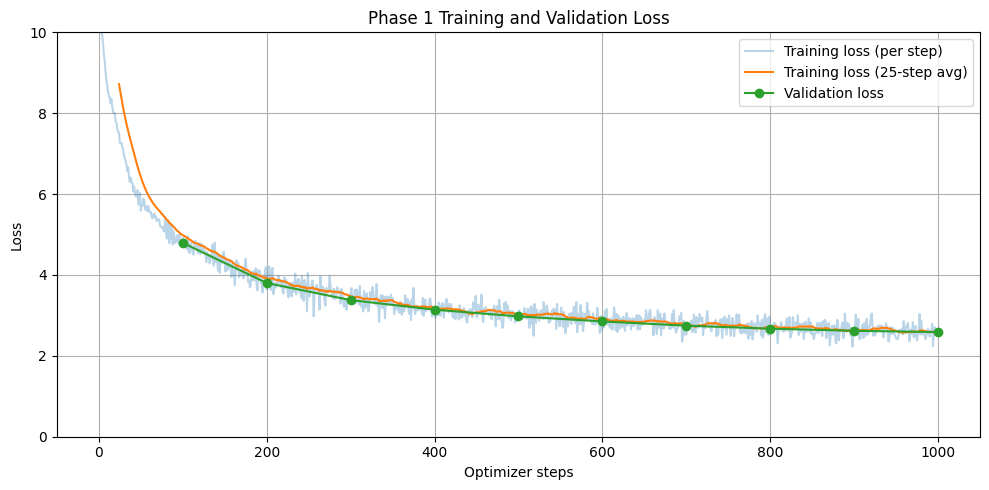

Loss plot saved to: /kaggle/working/cs781_phase1/training_validation_loss.png


In [23]:
import matplotlib.pyplot as plt
import numpy as np

tl = np.array(history["train_loss"])
k = 25
smooth = np.convolve(tl, np.ones(k) / k, mode="valid") if len(tl) > k else tl

plt.figure(figsize=(10, 5))
plt.plot(tl, alpha=0.3, label="Training loss (per step)")
plt.plot(range(k - 1, k - 1 + len(smooth)), smooth, label=f"Training loss ({k}-step avg)")
plt.plot(history["val_steps"], history["val_loss"], "o-", label="Validation loss")
plt.ylim(0, 10)
plt.xlabel("Optimizer steps"); plt.ylabel("Loss")
plt.title("Phase 1 Training and Validation Loss")
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=200)
plt.show()
print("Loss plot saved to:", LOSS_PLOT_PATH)

## 15. Push Model to Hugging Face Hub

In [24]:
HF_MODEL_REPO = "R-230834/CS-781-Capstone-Project/mla-sinusoidal-attn"

## 16. Load Test Data from HuggingFace

In [26]:
test_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TEST_FILE,
    repo_type="dataset",
    token=HF_TOKEN
)

print("Test file:", test_file_path)

test.json: 0.00B [00:00, ?B/s]

Test file: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Test/test.json


## 17. Load Test Prompts

In [27]:
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

print("Number of test examples:", len(test_data))

Number of test examples: 1000


## 18. Load Final Model for Generation

In [28]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

generation_model = model.to(device)
generation_model.eval()

print("Device:", device)
print(f"Parameters: {sum(p.numel() for p in generation_model.parameters()) / 1e6:.2f}M")

Device: cuda
Parameters: 190.02M


## 19. Generate 128 Words
#### (words, not tokens)

In [29]:
import torch

def generate_batch(prompts, model, tokenizer, device, target_words=128):
    special_ids = [tokenizer.stoi[t] for t in tokenizer.reserved]      # <pad>,<unk>,<s>,</s>
    pad_id = tokenizer.stoi["<pad>"]
    max_len_prompt = model.cfg.max_seq_len - MAX_GENERATION_TOKENS

    # FIX 1: tokenizer.encode() appends </s>. During training </s> means "document ended, a new
    # unrelated <s> document follows", so the old code asked the model to start a NEW document.
    # Keep <s>, drop the trailing </s>.
    encoded = []
    for p in prompts:
        ids = tokenizer.encode(p)[:-1]
        if len(ids) > max_len_prompt:                  # FIX 2: keep the END of a long prompt (not the start)
            ids = ids[:1] + ids[-(max_len_prompt - 1):]
        encoded.append(ids)

    # FIX 3: left-pad WITH an attention mask (old code let real tokens attend to untrained <pad> embeddings
    # and shifted every position by the pad length).
    L = max(len(e) for e in encoded)
    input_ids = torch.full((len(encoded), L), pad_id, dtype=torch.long)
    attn = torch.zeros((len(encoded), L), dtype=torch.long)
    for i, e in enumerate(encoded):
        input_ids[i, L - len(e):] = torch.tensor(e)
        attn[i, L - len(e):] = 1
    input_ids, attn = input_ids.to(device), attn.to(device)

    with torch.inference_mode(), torch.autocast("cuda", dtype=torch.float16, enabled=torch.cuda.is_available()):
        outputs = model.generate(
            input_ids, attention_mask=attn,
            max_new_tokens=MAX_GENERATION_TOKENS, temperature=TEMPERATURE, top_p=TOP_P,
            repetition_penalty=REPETITION_PENALTY, banned_token_ids=tuple(special_ids), do_sample=True)

    predictions = []
    for i in range(len(prompts)):
        text = tokenizer.decode(outputs[i, L:].tolist())
        predictions.append(" ".join(text.split()[:target_words]))
    return predictions

## 20. Generate Predictions for the Test Set

In [30]:
predictions = {}
GENERATION_BATCH_SIZE = 32

items = list(test_data.items())
total_examples = len(items)
print(f"Total test examples: {total_examples}")

for start in tqdm(range(0, total_examples, GENERATION_BATCH_SIZE)):
    batch = items[start : start + GENERATION_BATCH_SIZE]
    batch_ids = [str(example_id) for example_id, _ in batch]
    batch_prompts = [record["text"] for _, record in batch]

    batch_predictions = generate_batch(
        prompts=batch_prompts,
        model=generation_model,
        tokenizer=tokenizer,  # Pass the ByteLevelBPE instance itself, NOT tokenizer.encode
        device=device,
        target_words=128,
    )

    for example_id, prediction in zip(batch_ids, batch_predictions):
        predictions[example_id] = {"text": prediction}

    completed = start + len(batch)

Total test examples: 1000


100%|██████████| 32/32 [13:20<00:00, 25.02s/it]


## 21. Save prediction.json

In [31]:
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(
        predictions,
        f,
        ensure_ascii=False,
        indent=2
    )

print("prediction.json saved:")
print(PREDICTION_PATH)

prediction.json saved:
/kaggle/working/cs781_phase1/prediction.json


## 22. Create CodaBench Submission ZIP

In [32]:
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(PREDICTION_PATH, arcname="prediction.json")

print("Codabench submission created:")
print(SUBMISSION_ZIP)

Codabench submission created:
/kaggle/working/cs781_phase1/submission.zip


In [1]:
!zip model.zip ./cs781_phase1/swiglu-moe-rope-conv.pt

  adding: cs781_phase1/swiglu-moe-rope-conv.pt (deflated 9%)
